# Домашнее задание 6. Аппроксимация методом наименьших квадратов
**Колпакова Дарья Сергеевна, группа J3112, ИСУ 501390**

**Вариант 11**
Функция: $f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|})$ на отрезке $[-1; 2.5]$.

Необходимо построить аппроксимацию квадратным трёхчленом по 4-м точкам из заданного промежутка.
Ищем функцию в виде:
$g(x) = a_0 + a_1 x + a_2 x^2$

Базисные функции: $\varphi_0(x) = 1$, $\varphi_1(x) = x$, $\varphi_2(x) = x^2$.

Согласно методу наименьших квадратов, мы минимизируем сумму квадратов отклонений:
$S = \sum_{i=1}^{n} \left( y_i - \sum_{k=0}^{m} a_k \varphi_k(x_i) \right)^2 \to \min$
где $n=4$ (количество точек), $m=2$ (степень полинома).

Условие минимума $\frac{\partial S}{\partial a_j} = 0$ приводит к системе нормальных уравнений:
$\sum_{i=1}^{n} y_i \varphi_j(x_i) = \sum_{k=0}^{m} a_k \sum_{i=1}^{n} \varphi_k(x_i) \varphi_j(x_i), \quad j = 0, 1, 2$

В матричном виде эта система записывается как:
$(A^T A) \vec{a} = A^T \vec{y}$
где $A$ — матрица значений базисных функций в узлах (матрица Вандермонда для полиномов), $\vec{y}$ — вектор значений функции в узлах, а $\vec{a}$ — искомый вектор коэффициентов $(a_0, a_1, a_2)^T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Функция 11 варианта
def f(x):
    return 1/3 + np.cos(10 + 2.3**np.abs(x))

# Выбираем 4 точки из промежутка [-1, 2.5]
# Возьмем равномерно распределенные точки
x_nodes = np.linspace(-1, 2.5, 4)
y_nodes = f(x_nodes)

print("Выбранные узлы x:", np.round(x_nodes, 4))
print("Значения функции f(x) в узлах:", np.round(y_nodes, 4))

# Составляем матрицу базисных функций A
# Столбцы: phi_0(x)=1, phi_1(x)=x, phi_2(x)=x^2
A = np.vstack([np.ones_like(x_nodes), x_nodes, x_nodes**2]).T

print("\nМатрица A:")
print(np.round(A, 4))

# Составляем систему нормальных уравнений: (A^T * A) * a = A^T * y
ATA = A.T @ A
ATy = A.T @ y_nodes

print("\nМатрица системы нормальных уравнений (A^T * A):")
print(np.round(ATA, 4))
print("Вектор правой части (A^T * y):")
print(np.round(ATy, 4))

# Решаем систему и находим коэффициенты a0, a1, a2
a_coeffs = np.linalg.solve(ATA, ATy)

print("\nКоэффициенты аппроксимации (a0, a1, a2):")
print(np.round(a_coeffs, 4))

# Функция аппроксимации (квадратный трёхчлен)
def g(x):
    return a_coeffs[0] + a_coeffs[1]*x + a_coeffs[2]*x**2

Выбранные узлы x: [-1.      0.1667  1.3333  2.5   ]
Значения функции f(x) в узлах: [1.2981 0.4861 1.2251 1.0105]

Матрица A:
[[ 1.     -1.      1.    ]
 [ 1.      0.1667  0.0278]
 [ 1.      1.3333  1.7778]
 [ 1.      2.5     6.25  ]]

Матрица системы нормальных уравнений (A^T * A):
[[ 4.      3.      9.0556]
 [ 3.      9.0556 17.    ]
 [ 9.0556 17.     43.2238]]
Вектор правой части (A^T * y):
[4.0197 2.9426 9.8052]

Коэффициенты аппроксимации (a0, a1, a2):
[ 0.8879 -0.1752  0.1097]


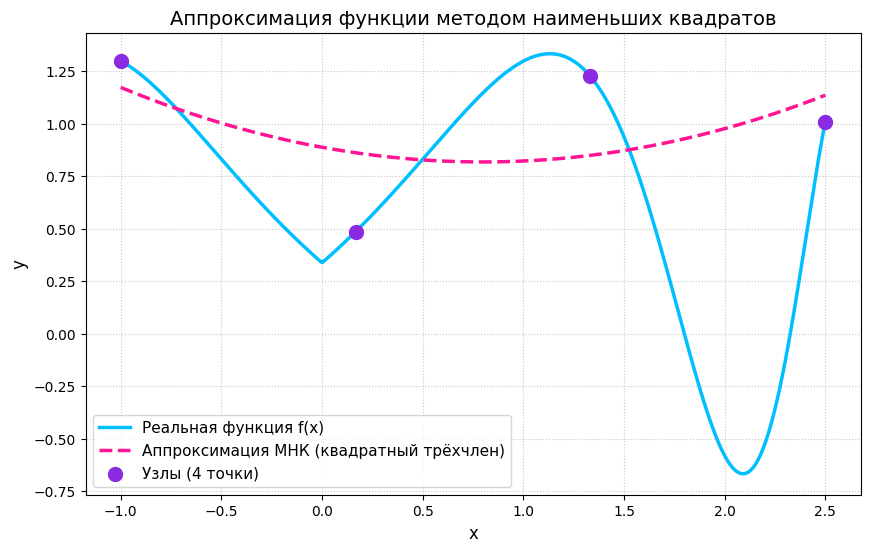

In [2]:
# Построение графиков
x_dense = np.linspace(-1, 2.5, 500)
y_exact = f(x_dense)
y_approx = g(x_dense)

plt.figure(figsize=(10, 6))

color_exact = '#00BFFF'
color_approx = '#FF1493'
color_nodes = '#8A2BE2'

plt.plot(x_dense, y_exact, label='Реальная функция f(x)', color=color_exact, linewidth=2.5)
plt.plot(x_dense, y_approx, label='Аппроксимация МНК (квадратный трёхчлен)', color=color_approx, linestyle='--', linewidth=2.5)
plt.scatter(x_nodes, y_nodes, color=color_nodes, s=100, zorder=5, label='Узлы (4 точки)')

plt.title('Аппроксимация функции методом наименьших квадратов', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.show()